<a href="https://colab.research.google.com/github/techievansh/beauty-wellness-data-science-internship/blob/main/Week-06/Beauty_Wellness_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

In [7]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/Dataset/beauty_reviews_cleaned.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Mounted at /content/drive
Dataset loaded successfully!
Dataset Shape: (10192, 12)


,user_id,item_id,rating,title,text,helpful_vote,verified_purchase,timestamp,review_date,title_clean,text_clean,review_length
0,AHCXZZ6R4US43PBVXXVN47OTTVHQ,B0002KHTCK,5.0,Best Toothbrush Available,I have been using the Braun Oral B 3D toothbru...,22,False,1103814114,2004-12-23 15:01:54+00:00,Best Toothbrush Available,I have been using the Braun Oral B 3D toothbru...,1966
1,AHUSGOTGVU5LFFPGCWLOTZ33RH7A,B0002KHTCK,5.0,Should have gotten this earlier,Just used this thing this morning and oh boy.....,7,False,1103819630,2004-12-23 16:33:50+00:00,Should have gotten this earlier,Just used this thing this morning and oh boy.....,394
2,AFL2ZDLKD6WRY5AG35RAWWKQTJFA,B000PKKAGO,4.0,Nice Shave...but beter than a razor?,At various times in my life I have rotated bet...,0,False,1197136923,2007-12-08 18:02:03+00:00,Nice Shave...but beter than a razor?,At various times in my life I have rotated bet...,1304
3,AG2C3CTEG3T7HPEKIZH2OQ54722Q,B000PKKAGO,5.0,Made me a Convert (from Razor Blades),I was skeptical about this shaver because of m...,1,False,1197389094,2007-12-11 16:04:54+00:00,Made me a Convert (from Razor Blades),I was skeptical about this shaver because of m...,2671
4,AHHWI6X47RXVMZOZCKRZCGZG36CQ,B000PKNPES,3.0,"Norelco is great, this one is just OK",I have used Norelco shavers for many years and...,19,False,1197724276,2007-12-15 13:11:16+00:00,"Norelco is great, this one is just OK",I have used Norelco shavers for many years and...,3554


In [8]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRating Distribution:")
print(df['rating'].value_counts().sort_index())

Columns:
['user_id', 'item_id', 'rating', 'title', 'text', 'helpful_vote', 'verified_purchase', 'timestamp', 'review_date', 'title_clean', 'text_clean', 'review_length']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10192 entries, 0 to 10191
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            10192 non-null  object 
 1   item_id            10192 non-null  object 
 2   rating             10192 non-null  float64
 3   title              10192 non-null  object 
 4   text               10192 non-null  object 
 5   helpful_vote       10192 non-null  int64  
 6   verified_purchase  10192 non-null  bool   
 7   timestamp          10192 non-null  int64  
 8   review_date        10192 non-null  object 
 9   title_clean        10192 non-null  object 
 10  text_clean         10182 non-null  object 
 11  review_length      10192 non-null  int64  
dtypes: bool(1), float64(1)

In [9]:
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df['sentiment'] = df['rating'].apply(assign_sentiment)

print("Sentiment labels created successfully!")
print(df[['rating', 'sentiment']].head(10))

Sentiment labels created successfully!
   rating sentiment
0     5.0  Positive
1     5.0  Positive
2     4.0  Positive
3     5.0  Positive
4     3.0   Neutral
5     3.0   Neutral
6     3.0   Neutral
7     4.0  Positive
8     4.0  Positive
9     5.0  Positive


sentiment
Positive    8371
Neutral     1100
Negative     721
Name: count, dtype: int64


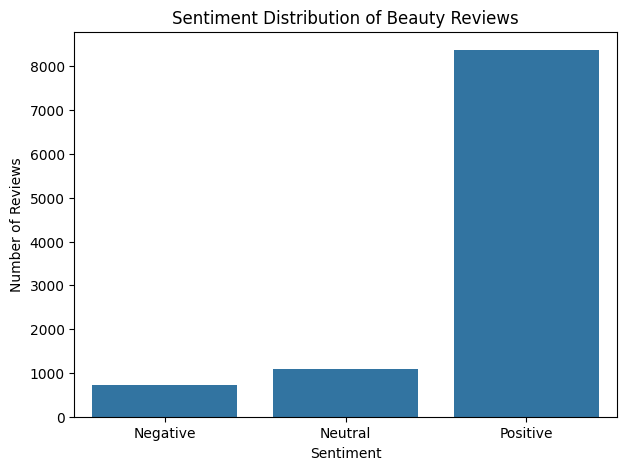

In [10]:
sentiment_counts = df['sentiment'].value_counts()

print(sentiment_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='sentiment', order=['Negative', 'Neutral', 'Positive'])
plt.title('Sentiment Distribution of Beauty Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [11]:
print(df[['title_clean', 'text_clean']].head())

                             title_clean  \
0              Best Toothbrush Available   
1        Should have gotten this earlier   
2   Nice Shave...but beter than a razor?   
3  Made me a Convert (from Razor Blades)   
4  Norelco is great, this one is just OK   

                                          text_clean  
0  I have been using the Braun Oral B 3D toothbru...  
1  Just used this thing this morning and oh boy.....  
2  At various times in my life I have rotated bet...  
3  I was skeptical about this shaver because of m...  
4  I have used Norelco shavers for many years and...  


In [12]:
df['combined_text'] = (
    df['title_clean'].fillna('').astype(str) + ' ' +
    df['text_clean'].fillna('').astype(str)
).str.strip()

df = df[df['combined_text'].str.len() > 0].copy()

print("Final Dataset Shape:", df.shape)
print(df[['combined_text', 'sentiment']].head())

Final Dataset Shape: (10192, 14)
                                       combined_text sentiment
0  Best Toothbrush Available I have been using th...  Positive
1  Should have gotten this earlier Just used this...  Positive
2  Nice Shave...but beter than a razor? At variou...  Positive
3  Made me a Convert (from Razor Blades) I was sk...  Positive
4  Norelco is great, this one is just OK I have u...   Neutral


In [13]:
X = df['combined_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 8153
Testing samples: 2039

Training sentiment distribution:
sentiment
Positive    6696
Neutral      880
Negative     577
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    1675
Neutral      220
Negative     144
Name: count, dtype: int64


In [16]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF transformation completed!
Training matrix shape: (8153, 5000)
Testing matrix shape: (2039, 5000)


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=30,
        class_weight='balanced',
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"{name} trained successfully!")

results_df = pd.DataFrame(results)
results_df = results_df.set_index("Model")

print("\nModel Training Completed!")
display(results_df.round(4))

Logistic Regression trained successfully!
Multinomial Naive Bayes trained successfully!
Decision Tree trained successfully!

Model Training Completed!


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966
Multinomial Naive Bayes,0.8225,0.8540,0.8225,0.7433
Decision Tree,0.7003,0.7667,0.7003,0.7268


In [19]:
from sklearn.metrics import classification_report

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=['Negative', 'Neutral', 'Positive'],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.42      0.55      0.47       144
     Neutral       0.30      0.48      0.37       220
    Positive       0.93      0.83      0.88      1675

    accuracy                           0.77      2039
   macro avg       0.55      0.62      0.57      2039
weighted avg       0.83      0.77      0.80      2039


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      0.01      0.01       144
     Neutral       1.00      0.00      0.01       220
    Positive       0.82      1.00      0.90      1675

    accuracy                           0.82      2039
   macro avg       0.94      0.34      0.31      2039
weighted avg       0.85      0.82      0.74      2039


Decision Tree
              precision    recall  f1-score   support

    Negative       0.24      0.52      0.33       144
     Neutral       0.18      0.21      0.19       220
    Positive  

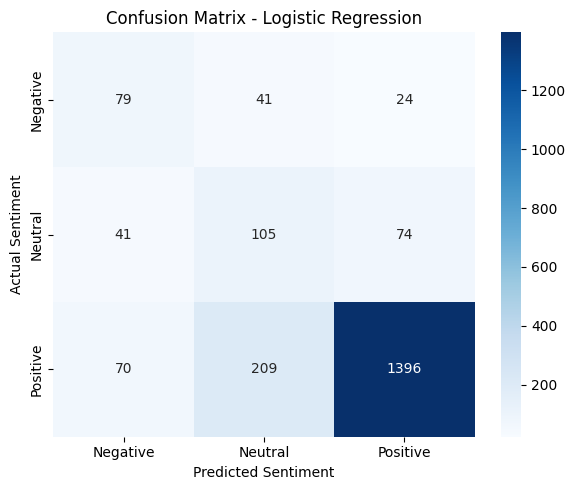

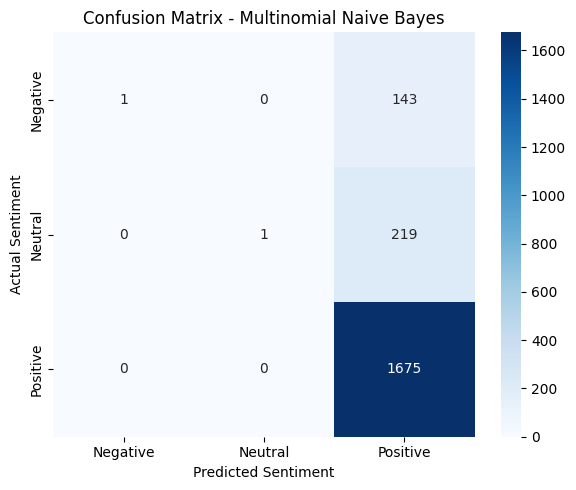

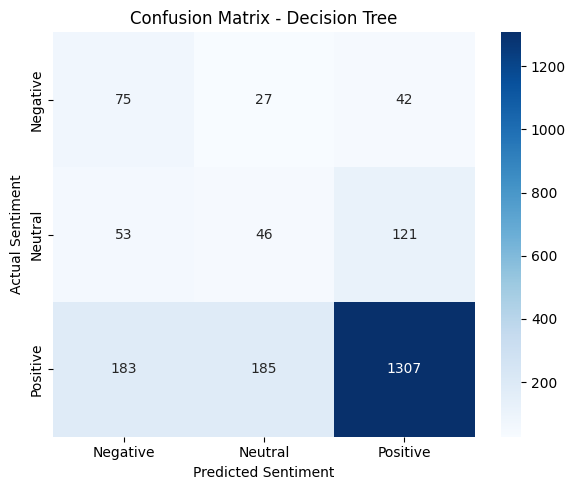

In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_labels = ['Negative', 'Neutral', 'Positive']

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Sentiment')
    plt.ylabel('Actual Sentiment')
    plt.tight_layout()
    plt.show()

In [21]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

nb_balanced = MultinomialNB()

nb_balanced.fit(
    X_train_tfidf,
    y_train,
    sample_weight=sample_weights
)

nb_balanced_pred = nb_balanced.predict(X_test_tfidf)

print("Balanced Naive Bayes Results:")
print(classification_report(
    y_test,
    nb_balanced_pred,
    labels=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

Balanced Naive Bayes Results:
              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47       144
     Neutral       0.27      0.58      0.37       220
    Positive       0.95      0.76      0.85      1675

    accuracy                           0.73      2039
   macro avg       0.54      0.65      0.56      2039
weighted avg       0.84      0.73      0.77      2039



In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

all_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Naive Bayes": models["Multinomial Naive Bayes"],
    "Decision Tree": models["Decision Tree"],
    "Balanced Naive Bayes": nb_balanced
}

comparison = []

for name, model in all_models.items():

    predictions = model.predict(X_test_tfidf)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted Precision": precision_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average='macro', zero_division=0
        )
    })

final_results = pd.DataFrame(comparison).set_index("Model")

display(final_results.round(4))

,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
Model,,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966,0.5731
Naive Bayes,0.8225,0.8540,0.8225,0.7433,0.3084
Decision Tree,0.7003,0.7667,0.7003,0.7268,0.4511
Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624


In [23]:
final_results.to_csv("Week_05_Final_Model_Comparison.csv")

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Balanced Naive Bayes": nb_balanced
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train_tfidf,
        y_train,
        cv=cv,
        scoring=['accuracy', 'f1_weighted', 'f1_macro'],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores['test_accuracy'].mean(),
        "Accuracy Std": scores['test_accuracy'].std(),
        "Mean Weighted F1": scores['test_f1_weighted'].mean(),
        "Mean Macro F1": scores['test_f1_macro'].mean()
    })

cv_df = pd.DataFrame(cv_results).set_index("Model")

display(cv_df.round(4))

,Mean Accuracy,Accuracy Std,Mean Weighted F1,Mean Macro F1
Model,,,,
Logistic Regression,0.7932,0.0110,0.8106,0.5971
Balanced Naive Bayes,0.8222,0.0006,0.7430,0.3099


In [25]:
cv_df.to_csv("Week_05_Cross_Validation_Results.csv")

print("Cross-validation results saved successfully!")

Cross-validation results saved successfully!


In [26]:
print("FINAL MODEL COMPARISON")
display(final_results.round(4))

print("\n5-FOLD CROSS VALIDATION")
display(cv_df.round(4))

FINAL MODEL COMPARISON


,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
Model,,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966,0.5731
Naive Bayes,0.8225,0.8540,0.8225,0.7433,0.3084
Decision Tree,0.7003,0.7667,0.7003,0.7268,0.4511
Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624



5-FOLD CROSS VALIDATION


,Mean Accuracy,Accuracy Std,Mean Weighted F1,Mean Macro F1
Model,,,,
Logistic Regression,0.7932,0.0110,0.8106,0.5971
Balanced Naive Bayes,0.8222,0.0006,0.7430,0.3099


In [28]:
import joblib
import os

os.makedirs("Week_05_Outputs/Models", exist_ok=True)

joblib.dump(
    models["Logistic Regression"],
    "Week_05_Outputs/Models/logistic_regression_model.pkl"
)

joblib.dump(
    tfidf,
    "Week_05_Outputs/Models/tfidf_vectorizer.pkl"
)

print("Logistic Regression model saved!")
print("TF-IDF vectorizer saved!")

Logistic Regression model saved!
TF-IDF vectorizer saved!


In [29]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("Week_05_Outputs/Reports", exist_ok=True)
os.makedirs("Week_05_Outputs/Visualizations", exist_ok=True)

for name, model in all_models.items():

    predictions = model.predict(X_test_tfidf)

    safe_name = name.lower().replace(" ", "_")

    report = classification_report(
        y_test,
        predictions,
        labels=['Negative', 'Neutral', 'Positive'],
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        f"Week_05_Outputs/Reports/{safe_name}_report.csv"
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=['Negative', 'Neutral', 'Positive']
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Neutral', 'Positive'],
        yticklabels=['Negative', 'Neutral', 'Positive']
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()

    plt.savefig(
        f"Week_05_Outputs/Visualizations/{safe_name}_confusion_matrix.png"
    )
    plt.close()

print("Evaluation reports and confusion matrices saved!")

Evaluation reports and confusion matrices saved!


In [30]:
import shutil

shutil.make_archive(
    "Week_05_Complete_Outputs",
    "zip",
    "Week_05_Outputs"
)

print("Week 5 outputs ZIP created successfully!")

Week 5 outputs ZIP created successfully!


In [31]:
from google.colab import files

files.download("Week_05_Complete_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
files.download("Week_05_Final_Model_Comparison.csv")
files.download("Week_05_Cross_Validation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
from google.colab import files

files.download("Week_05_Cross_Validation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
# Check important variables already available in your notebook

variables_to_check = [
    'X_train_tfidf',
    'X_test_tfidf',
    'y_train',
    'y_test',
    'lr_model',
    'nb_model',
    'dt_model',
    'balanced_nb_model'
]

for var in variables_to_check:
    print(f"{var}: {'Available' if var in globals() else 'Not Available'}")

X_train_tfidf: Available
X_test_tfidf: Available
y_train: Available
y_test: Available
lr_model: Not Available
nb_model: Not Available
dt_model: Not Available
balanced_nb_model: Not Available


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize
from sklearn.model_selection import cross_val_score

import os

os.makedirs("Week-06", exist_ok=True)

print("Week 6 evaluation environment is ready!")

Week 6 evaluation environment is ready!


In [39]:
from sklearn.base import BaseEstimator

print("TRAINED MODELS FOUND:\n")

trained_models = {}

for name, obj in globals().copy().items():
    if isinstance(obj, BaseEstimator) and hasattr(obj, "predict"):
        trained_models[name] = obj
        print(f"{name} : {type(obj).__name__}")

print("\nTotal models found:", len(trained_models))

TRAINED MODELS FOUND:

model : MultinomialNB
nb_balanced : MultinomialNB

Total models found: 2


In [40]:
print("DATA VARIABLES:")

for name, obj in globals().copy().items():
    try:
        if hasattr(obj, "shape"):
            print(name, ":", obj.shape)
    except:
        pass

DATA VARIABLES:
_ : (5, 12)
np : <function shape at 0x7a247657cc20>
df : (10192, 14)
_7 : (5, 12)
sentiment_counts : (3,)
X : (10192,)
y : (10192,)
X_train : (8153,)
X_test : (2039,)
y_train : (8153,)
y_test : (2039,)
X_train_tfidf : (8153, 5000)
X_test_tfidf : (2039, 5000)
y_pred : (2039,)
results_df : (3, 4)
cm : (3, 3)
sample_weights : (8153,)
nb_balanced_pred : (2039,)
predictions : (2039,)
final_results : (4, 5)
cv_df : (2, 4)


In [41]:
print("Multinomial NB:", model)
print("Balanced NB:", nb_balanced)

print("\nModel classes:")
print("Multinomial NB:", model.classes_)
print("Balanced NB:", nb_balanced.classes_)

Multinomial NB: MultinomialNB()
Balanced NB: MultinomialNB()

Model classes:
Multinomial NB: ['Negative' 'Neutral' 'Positive']
Balanced NB: ['Negative' 'Neutral' 'Positive']


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

for name, obj in globals().copy().items():
    if isinstance(obj, (LogisticRegression, DecisionTreeClassifier)):
        print(name, ":", type(obj).__name__)

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB

model_candidates = {}

for name, obj in globals().copy().items():
    if isinstance(obj, (LogisticRegression, DecisionTreeClassifier, MultinomialNB)):
        model_candidates[name] = obj
        print(f"{name}: {type(obj).__name__}")

print("\nTotal candidate models:", len(model_candidates))

model: MultinomialNB
nb_balanced: MultinomialNB

Total candidate models: 2


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "Multinomial Naive Bayes": model,
    "Balanced Naive Bayes": nb_balanced
}

evaluation_results = []

for name, clf in models.items():

    predictions = clf.predict(X_test_tfidf)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

    print("\n", "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        predictions,
        labels=clf.classes_,
        zero_division=0
    ))

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47       144
     Neutral       0.27      0.58      0.37       220
    Positive       0.95      0.76      0.85      1675

    accuracy                           0.73      2039
   macro avg       0.54      0.65      0.56      2039
weighted avg       0.84      0.73      0.77      2039


Balanced Naive Bayes
              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47       144
     Neutral       0.27      0.58      0.37       220
    Positive       0.95      0.76      0.85      1675

    accuracy                           0.73      2039
   macro avg       0.54      0.65      0.56      2039
weighted avg       0.84      0.73      0.77      2039



,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,Multinomial Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624
1,Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624


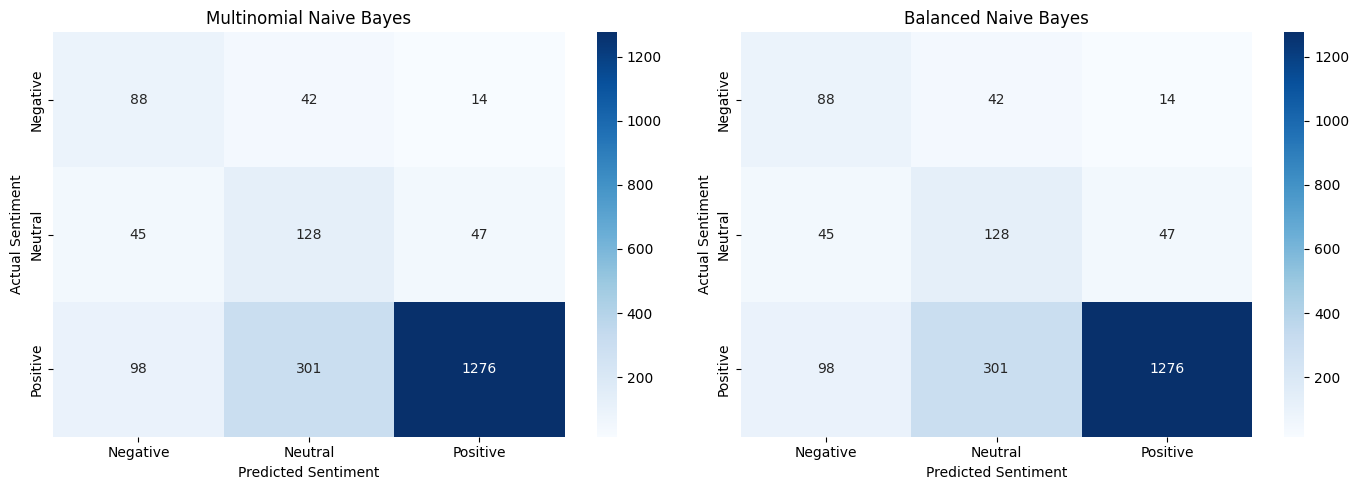

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, clf) in zip(axes, models.items()):

    predictions = clf.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=clf.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=clf.classes_,
        yticklabels=clf.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.savefig("confusion_matrices_week6.png", dpi=300)
plt.show()

In [51]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

classes = np.array(["Negative", "Neutral", "Positive"])

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

roc_results = []

for name, clf in models.items():

    probabilities = clf.predict_proba(X_test_tfidf)

    score = roc_auc_score(
        y_test_binary,
        probabilities,
        multi_class="ovr",
        average="macro"
    )

    roc_results.append({
        "Model": name,
        "Macro ROC-AUC": score
    })

roc_df = pd.DataFrame(roc_results).set_index("Model")

display(roc_df.round(4))

,Macro ROC-AUC
Model,
Multinomial Naive Bayes,0.8476
Balanced Naive Bayes,0.8476


In [52]:
import os

os.makedirs("Week-06", exist_ok=True)

evaluation_df.to_csv(
    "Week-06/model_evaluation_results.csv",
    index=False
)

roc_df.to_csv(
    "Week-06/roc_auc_results.csv",
    index=False
)

print("Week 6 evaluation results saved successfully!")

Week 6 evaluation results saved successfully!


In [53]:
print("WEEK 6 MODEL EVALUATION")
display(evaluation_df.round(4))

print("\nROC-AUC RESULTS")
display(roc_df.round(4))

WEEK 6 MODEL EVALUATION


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,Multinomial Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624
1,Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624



ROC-AUC RESULTS


,Macro ROC-AUC
Model,
Multinomial Naive Bayes,0.8476
Balanced Naive Bayes,0.8476


In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

# Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=30,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train_tfidf, y_train)

print("Logistic Regression and Decision Tree trained successfully!")

Logistic Regression and Decision Tree trained successfully!


In [55]:
models = {
    "Logistic Regression": lr_model,
    "Multinomial Naive Bayes": model,
    "Decision Tree": dt_model,
    "Balanced Naive Bayes": nb_balanced
}

print("Total models:", len(models))

Total models: 4


In [56]:
pred_nb = model.predict(X_test_tfidf)
pred_balanced = nb_balanced.predict(X_test_tfidf)

print("Same predictions:", np.array_equal(pred_nb, pred_balanced))
print("Multinomial NB parameters:", model.get_params())
print("Balanced NB parameters:", nb_balanced.get_params())

Same predictions: True
Multinomial NB parameters: {'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Balanced NB parameters: {'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}


In [57]:
models = {
    "Logistic Regression": lr_model,
    "Multinomial Naive Bayes": model,
    "Decision Tree": dt_model,
    "Balanced Naive Bayes": nb_balanced
}

evaluation_results = []
all_predictions = {}

for name, clf in models.items():

    y_pred = clf.predict(X_test_tfidf)
    all_predictions[name] = y_pred

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Weighted Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    ))

evaluation_df = pd.DataFrame(evaluation_results)

print("\nFINAL FOUR-MODEL COMPARISON")
display(evaluation_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.42      0.55      0.47       144
     Neutral       0.30      0.48      0.37       220
    Positive       0.93      0.83      0.88      1675

    accuracy                           0.77      2039
   macro avg       0.55      0.62      0.57      2039
weighted avg       0.83      0.77      0.80      2039


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47       144
     Neutral       0.27      0.58      0.37       220
    Positive       0.95      0.76      0.85      1675

    accuracy                           0.73      2039
   macro avg       0.54      0.65      0.56      2039
weighted avg       0.84      0.73      0.77      2039


Decision Tree
              precision    recall  f1-score   support

    Negative       0.24      0.52      0.33       144
     Neutral       0.18      0.21      0.19       220
    Positive  

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,Logistic Regression,0.7749,0.8289,0.7749,0.7966,0.5731
1,Multinomial Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624
2,Decision Tree,0.7003,0.7667,0.7003,0.7268,0.4511
3,Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624


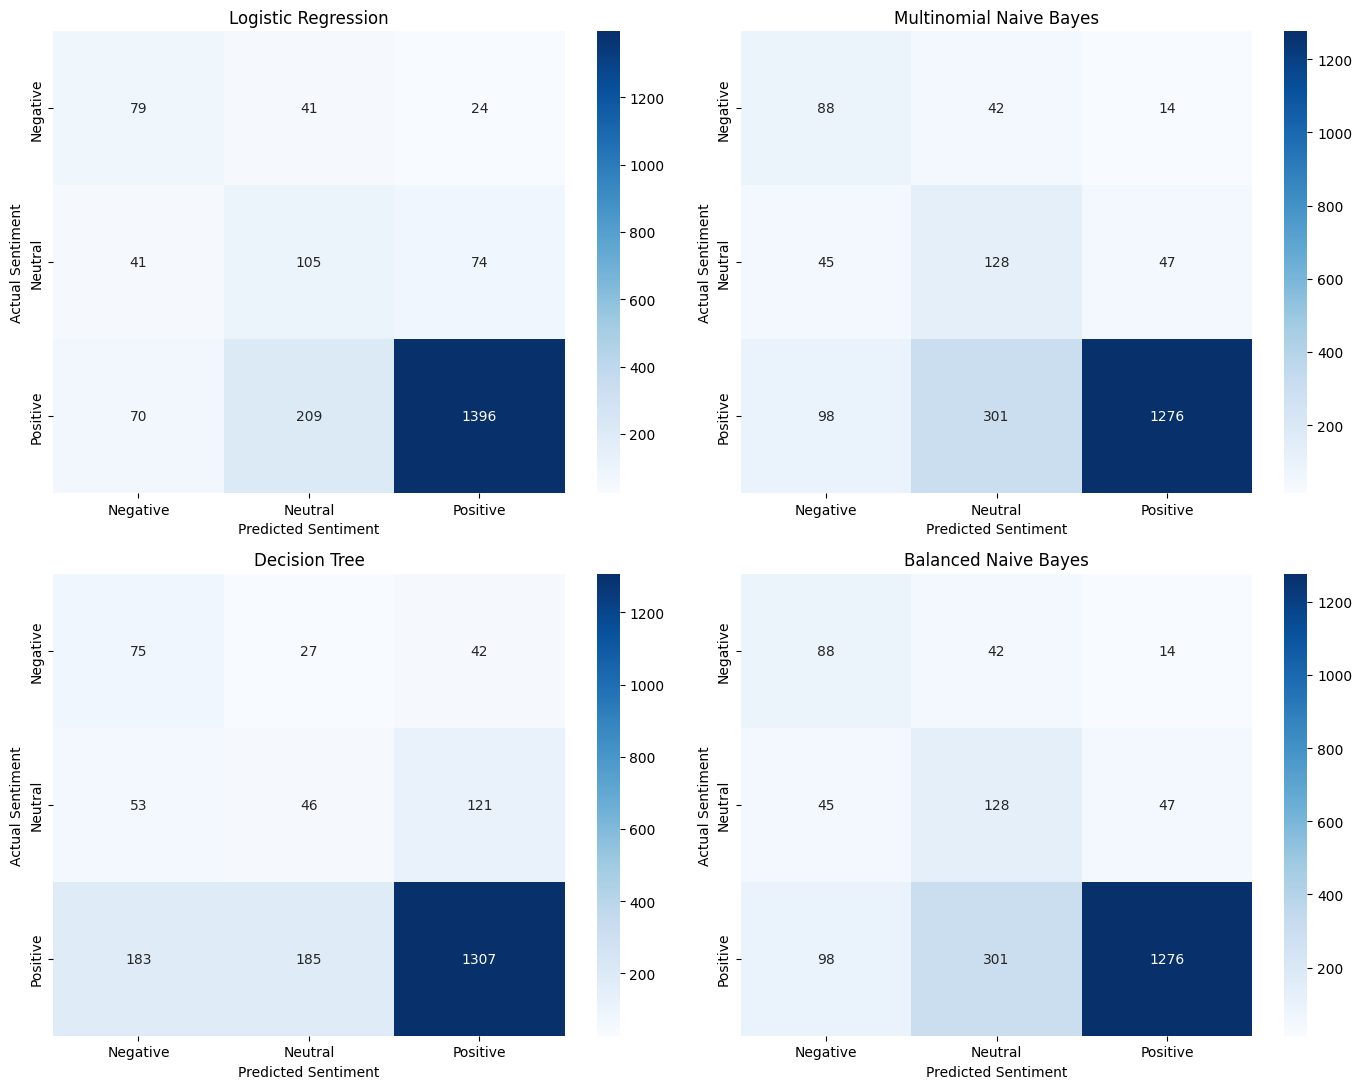

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, y_pred) in zip(axes.flatten(), all_predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.savefig("Week-06/four_model_confusion_matrices.png", dpi=300)
plt.show()

In [59]:
roc_results = []

for name, clf in models.items():

    if not hasattr(clf, "predict_proba"):
        print(name, "- Probability scores unavailable")
        continue

    probabilities = clf.predict_proba(X_test_tfidf)

    class_order = list(clf.classes_)
    expected_classes = ["Negative", "Neutral", "Positive"]

    # Ensure probability columns follow the correct class order
    probabilities = probabilities[
        :, [class_order.index(c) for c in expected_classes]
    ]

    y_binary = label_binarize(
        y_test,
        classes=expected_classes
    )

    score = roc_auc_score(
        y_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )

    roc_results.append({
        "Model": name,
        "Macro ROC-AUC": score
    })

roc_df = pd.DataFrame(roc_results)

print("FOUR-MODEL ROC-AUC COMPARISON")
display(roc_df.round(4))

FOUR-MODEL ROC-AUC COMPARISON


,Model,Macro ROC-AUC
0,Logistic Regression,0.8540
1,Multinomial Naive Bayes,0.8476
2,Decision Tree,0.6447
3,Balanced Naive Bayes,0.8476


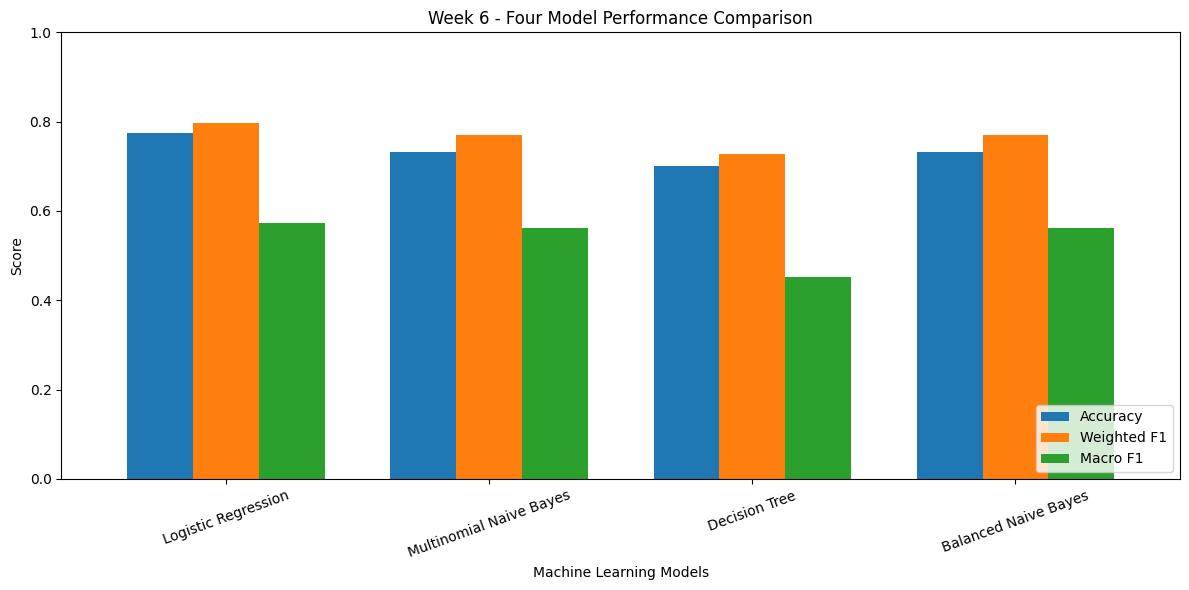

In [61]:
metrics = ["Accuracy", "Weighted F1", "Macro F1"]

evaluation_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("Week 6 - Four Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("Week-06/four_model_performance.png", dpi=300)
plt.show()

In [62]:
evaluation_df.to_csv(
    "Week-06/final_model_evaluation.csv",
    index=False
)

roc_df.to_csv(
    "Week-06/final_roc_auc_results.csv",
    index=False
)

print("All four-model evaluation results saved successfully!")

All four-model evaluation results saved successfully!


In [63]:
print("FINAL ROC-AUC RESULTS")
display(roc_df.round(4))

FINAL ROC-AUC RESULTS


,Model,Macro ROC-AUC
0,Logistic Regression,0.8540
1,Multinomial Naive Bayes,0.8476
2,Decision Tree,0.6447
3,Balanced Naive Bayes,0.8476


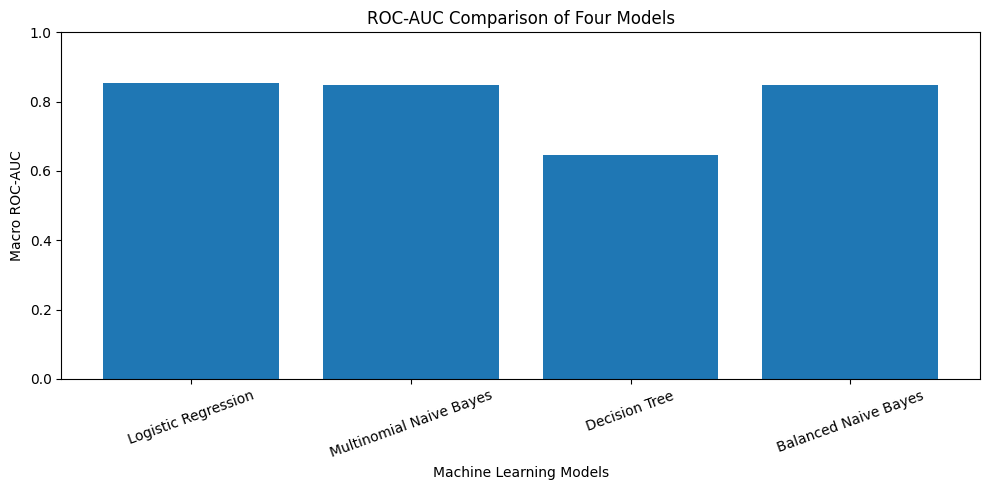

In [64]:
plt.figure(figsize=(10, 5))

plt.bar(
    roc_df["Model"],
    roc_df["Macro ROC-AUC"]
)

plt.title("ROC-AUC Comparison of Four Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Macro ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "Week-06/roc_auc_comparison.png",
    dpi=300
)

plt.show()

In [65]:
import os

os.makedirs("Week-06", exist_ok=True)

evaluation_df.to_csv(
    "Week-06/final_model_evaluation.csv",
    index=False
)

roc_df.to_csv(
    "Week-06/final_roc_auc_results.csv",
    index=False
)

for name, predictions in all_predictions.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    pd.DataFrame({
        "Actual": y_test,
        "Predicted": predictions
    }).to_csv(
        f"Week-06/{filename}_predictions.csv",
        index=False
    )

print("All evaluation files exported successfully!")

All evaluation files exported successfully!


In [66]:
import os

output_dir = "Week-06/Graphs"
os.makedirs(output_dir, exist_ok=True)

print("Graph folder created:", output_dir)

Graph folder created: Week-06/Graphs


<Figure size 1200x600 with 0 Axes>

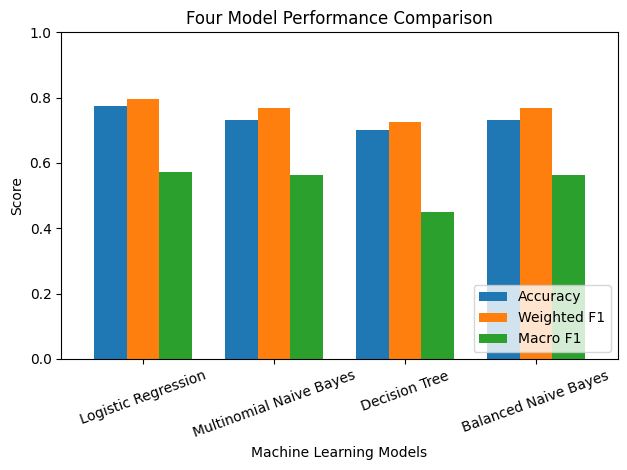

In [67]:
plt.figure(figsize=(12, 6))

evaluation_df.set_index("Model")[
    ["Accuracy", "Weighted F1", "Macro F1"]
].plot(kind="bar", width=0.75)

plt.title("Four Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/01_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

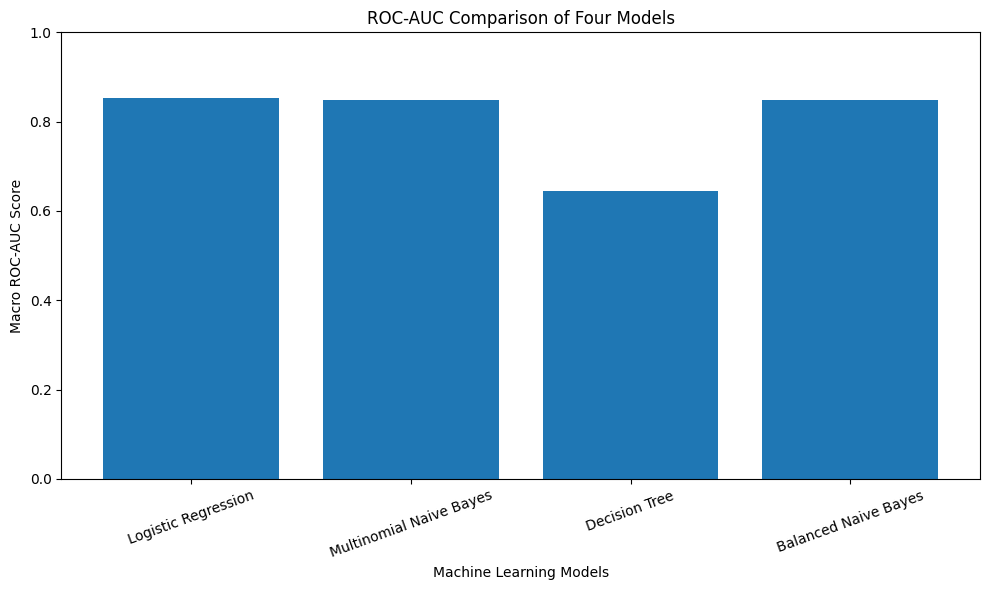

In [68]:
plt.figure(figsize=(10, 6))

plt.bar(
    roc_df["Model"],
    roc_df["Macro ROC-AUC"]
)

plt.title("ROC-AUC Comparison of Four Models")
plt.ylabel("Macro ROC-AUC Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/02_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

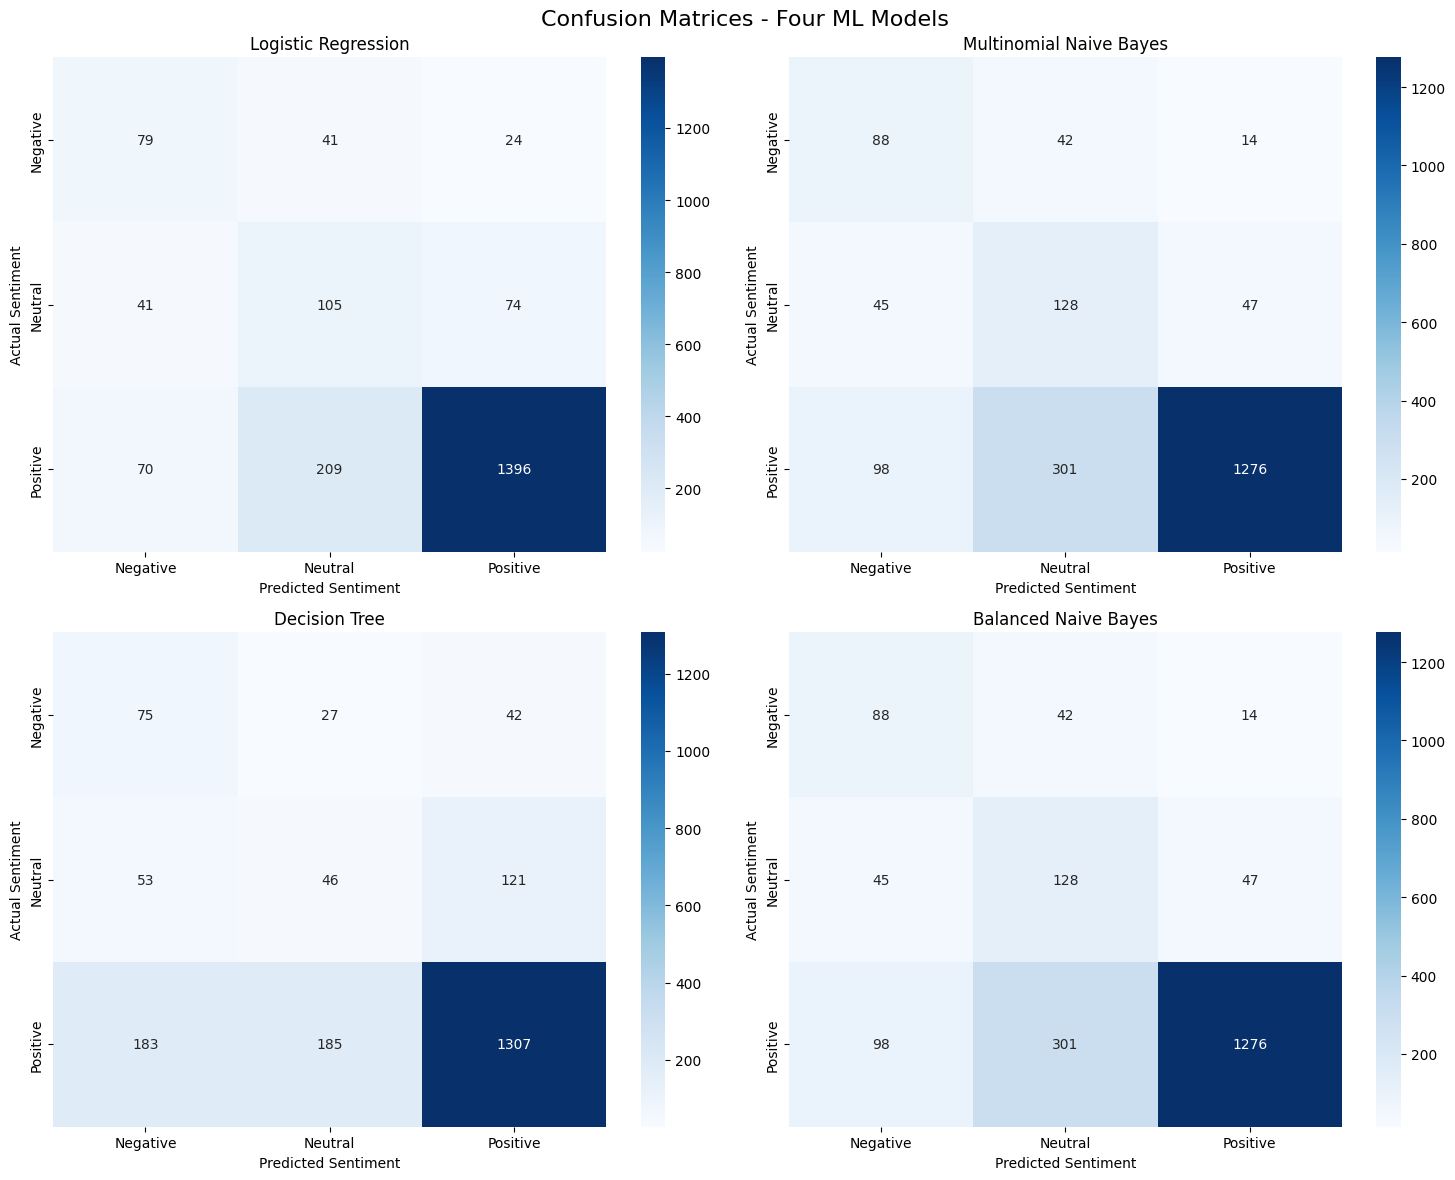

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, (name, predictions) in zip(
    axes.flatten(), all_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["Negative", "Neutral", "Positive"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.suptitle("Confusion Matrices - Four ML Models", fontsize=16)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/03_four_model_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

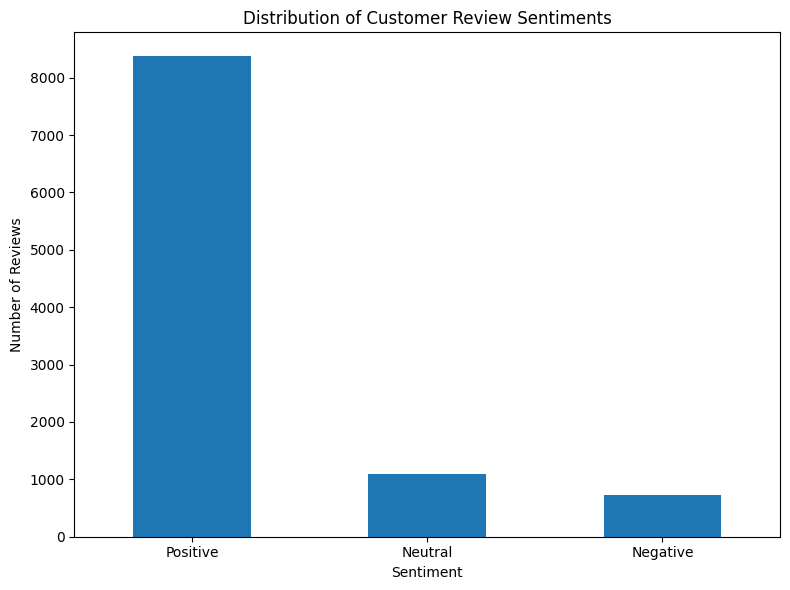

In [70]:
plt.figure(figsize=(8, 6))

sentiment_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Distribution of Customer Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/04_sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

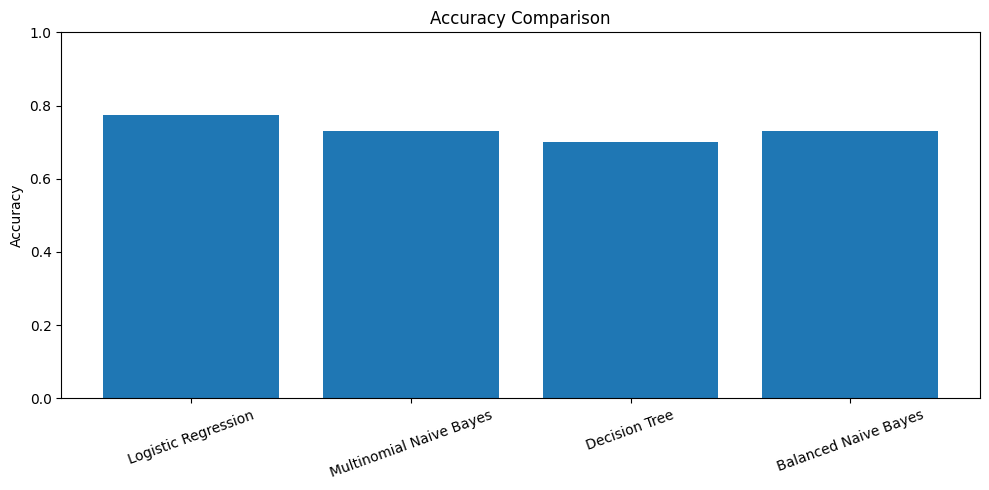

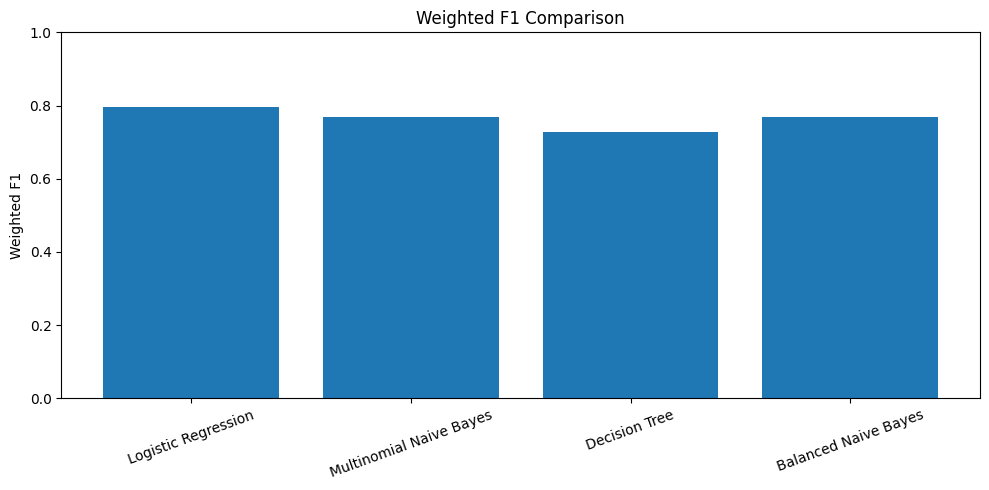

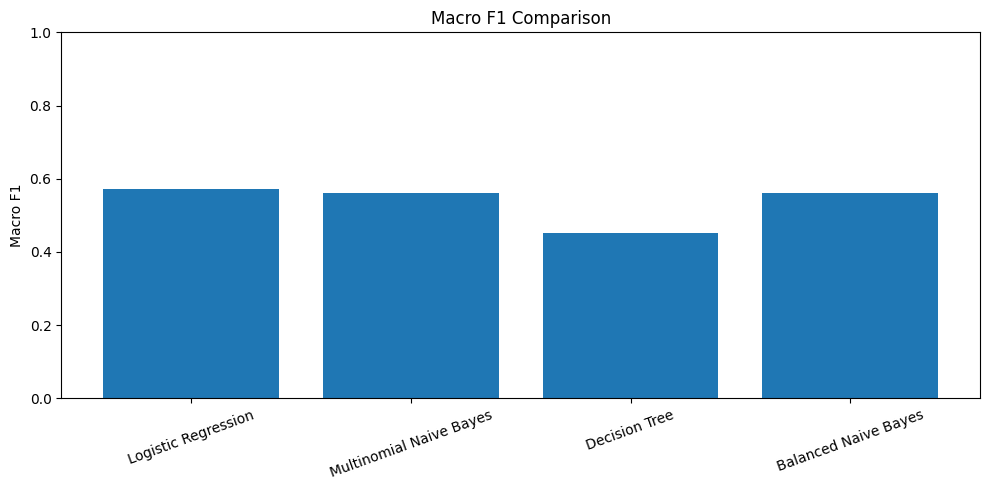

In [71]:
for metric in ["Accuracy", "Weighted F1", "Macro F1"]:

    plt.figure(figsize=(10, 5))

    plt.bar(
        evaluation_df["Model"],
        evaluation_df[metric]
    )

    plt.title(f"{metric} Comparison")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()

    filename = metric.lower().replace(" ", "_")

    plt.savefig(
        f"{output_dir}/05_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [72]:
print("SAVED WEEK 6 GRAPHS:\n")

for file in sorted(os.listdir(output_dir)):
    print(file)

print("\nTotal graph images:", len(os.listdir(output_dir)))

SAVED WEEK 6 GRAPHS:

01_model_performance_comparison.png
02_roc_auc_comparison.png
03_four_model_confusion_matrices.png
04_sentiment_distribution.png
05_accuracy.png
05_macro_f1.png
05_weighted_f1.png

Total graph images: 7


In [73]:
import shutil

shutil.make_archive(
    "Week_06_Graphs",
    "zip",
    "Week-06"
)

from google.colab import files

files.download("Week_06_Graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>